# Voix du client : qui sont les TPE-PME face à la facturation électronique ?

**Auteure :** N. Danielle OUATTARA · **Données :** [Baromètre France Num 2022](https://www.data.gouv.fr/datasets/france-num-barometre-2022-libelles-des-questions-et-resultats-1) (DGE, enquête CREDOC), Licence Ouverte 2.0

**Question :** parmi les 4 671 dirigeants interrogés, quels groupes se distinguent par leur équipement, leurs freins et leur budget ? Ces groupes serviront de base aux personas de l'offre de facturation électronique (nom retenu : **Duo Facture**).

| Étape | Contenu |
|---|---|
| 1 | Import des données |
| 2 | Mise en forme : une ligne par entreprise |
| 3 | Indicateurs pondérés |
| 4 | Équipées et non équipées : ce qui les distingue |
| 5 | Segmentation en trois groupes |
| 6 | Profil de chaque segment |
| 7 | Prescripteurs : qui conseille chaque segment |
| 8 | Conclusion |

> Toutes les proportions sont **pondérées** par la variable `POIDS`, pour être représentatives des TPE-PME françaises et non du seul échantillon.

## 1. Import des données

In [1]:
import pandas as pd                      # pandas : la bibliothèque qui manipule des tableaux (comme Excel)
import numpy as np                       # numpy : calculs numériques, ici pour les moyennes pondérées
import matplotlib.pyplot as plt          # matplotlib : la bibliothèque qui dessine les graphiques

colonnes = ["id", "POIDS", "Question", "Libelle Réponse", "Taille Etablissement"]   # seules colonnes utiles : le fichier complet pèse 240 Mo
brut = pd.read_csv("../data/bfn-resultats-2022.csv",   # chemin du fichier téléchargé sur data.gouv.fr
                   sep=";",                            # le fichier utilise le point-virgule comme séparateur
                   usecols=colonnes,                   # ne charge que les colonnes listées, pour aller plus vite
                   dtype=str)                          # lit tout en texte ; on convertira les nombres ensuite

print(brut.shape)                        # (nombre de lignes, nombre de colonnes) : une ligne par entreprise ET par question
print(brut["id"].nunique())              # nombre d'entreprises distinctes : on attend 4671

(358685, 5)
4671


## 2. Mise en forme : une ligne par entreprise

Le fichier est au format « long » : chaque réponse est une ligne. On le transforme en tableau « large », une ligne par entreprise et une colonne par question, comme un fichier Excel classique.

In [2]:
questions = {                            # dictionnaire : code de la question -> nom de colonne lisible
    "Q4_23": "facturation",              # solution de facturation : j'en ai / je prévois / je n'en ai pas
    "Q4_22": "comptabilite",             # solution de gestion comptable
    "Q5_7": "part_efacture",             # part des factures émises en format électronique structuré
    "Q6_2": "budget",                    # budget consacré au numérique l'année précédente
    "Q3_3": "benefice",                  # « le numérique représente un bénéfice réel pour mon entreprise »
    "Q3_6": "perte_temps",               # « le numérique me fait perdre plus de temps qu'il ne m'en fait gagner »
    "Q3_10": "peur_piratage",            # « j'ai peur de perdre ou de me faire pirater des données »
    "Q3_11": "en_retard",                # « je suis en retard sur le numérique par rapport à mon secteur »
    "Q7_1": "conseil",                   # qui serait le mieux à même de vous conseiller (plusieurs réponses possibles)
    "Q1_5": "secteur",                   # secteur d'activité
}

reponses = brut[brut["Question"].isin(questions)]                 # garde uniquement les questions retenues
large = reponses.pivot_table(index="id",                          # une ligne par entreprise
                             columns="Question",                  # une colonne par question
                             values="Libelle Réponse",            # la valeur de chaque case = la réponse
                             aggfunc="first")                     # une seule réponse par case : on prend la première
large = large.rename(columns=questions)                           # remplace les codes (Q4_23…) par des noms lisibles

infos = brut.drop_duplicates("id").set_index("id")[["POIDS", "Taille Etablissement"]]   # poids et taille, une fois par entreprise
df = infos.join(large)                                            # assemble les deux tableaux sur l'identifiant
df["POIDS"] = df["POIDS"].astype(float)                           # convertit le poids en nombre
df = df.rename(columns={"Taille Etablissement": "taille"})        # nom de colonne plus court

print(df.shape)                          # on attend 4671 lignes
df.head()                                # aperçu des 5 premières entreprises

(4671, 12)


,POIDS,taille,secteur,peur_piratage,en_retard,benefice,perte_temps,comptabilite,facturation,part_efacture,budget,conseil
id,,,,,,,,,,,,
n176,1825.360218,0 salarié,Bâtiment - Construction,Tout à fait d'accord,Ni en accord ni en désaccord,Tout à fait d'accord,Pas du tout d'accord,J'en ai,J'en ai,Plus de 50%,C - De 1000 à 2000 euros,"France Num, l'initiative de la direction génér..."
n202,1824.300516,1 à 9 salariés,Commerce (détail et gros),Plutôt pas d'accord,Ni en accord ni en désaccord,Ni en accord ni en désaccord,Plutôt pas d'accord,J'en ai,J'en ai,0%,B - De 2000 à 5000 euros,Mes réseaux personnels ou familiaux
n204,1824.300516,1 à 9 salariés,Commerce (détail et gros),Ni en accord ni en désaccord,Ni en accord ni en désaccord,Plutôt d'accord,Ni en accord ni en désaccord,J'en ai,J'en ai,F - De 30% à 49%,G - Aucun,Je n'ai pas de réels projets
n9,805.051127,1 à 9 salariés,Activités financières - Assurances,Plutôt d'accord,Plutôt pas d'accord,Plutôt d'accord,Plutôt pas d'accord,•Je n'en ai pas et n'en prévois pas pour l'ins...,•Je n'en ai pas et n'en prévois pas pour l'ins...,NaN,C - De 1000 à 2000 euros,Mes réseaux professionnels (prestataires…)
n15,451.284842,0 salarié,Activités financières - Assurances,Plutôt pas d'accord,Pas du tout d'accord,Tout à fait d'accord,Pas du tout d'accord,•Je n'en ai pas et n'en prévois pas pour l'ins...,Je prévois d'en avoir dans les 12 mois,NaN,D - De 500 à 1000 euros,Je n'ai pas de réels projets


### Recodage en indicateurs 0 / 1

Chaque réponse est transformée en indicateur oui (1) / non (0). La moyenne d'un indicateur 0/1 donne directement un pourcentage.

In [3]:
accord = ["Tout à fait d'accord", "Plutôt d'accord"]              # réponses comptées comme « d'accord » sur l'échelle à 5 points

df["equipee"] = (df["facturation"] == "J'en ai").astype(int)                         # 1 si l'entreprise a une solution de facturation
df["compta"] = (df["comptabilite"] == "J'en ai").astype(int)                         # 1 si elle a une solution comptable
df["petit_budget"] = np.where(df["budget"].isna(), np.nan,                          # vide si le dirigeant n'a pas répondu sur le budget
                              df["budget"].str[0].isin(["E", "F", "G"]))         # sinon 1 si budget de 500 € ou moins (codes E, F, G), 0 au-delà
df["benefice_ok"] = df["benefice"].isin(accord).astype(int)                          # 1 si le dirigeant voit un bénéfice réel au numérique
df["perte_temps_ok"] = df["perte_temps"].isin(accord).astype(int)                    # 1 s'il pense que le numérique lui fait perdre du temps
df["peur_ok"] = df["peur_piratage"].isin(accord).astype(int)                         # 1 s'il craint la perte ou le piratage de données
df["retard_ok"] = df["en_retard"].isin(accord).astype(int)                           # 1 s'il se sent en retard sur son secteur
df["sans_projet"] = df["conseil"].str.contains("pas de réels projets", na=False).astype(int)        # 1 s'il déclare n'avoir aucun projet numérique
df["conseil_reseau_pro"] = df["conseil"].str.contains("réseaux professionnels", na=False).astype(int)  # 1 s'il cite ses réseaux professionnels
df["conseil_perso"] = df["conseil"].str.contains("réseaux personnels", na=False).astype(int)        # 1 s'il cite ses réseaux personnels ou familiaux
df["conseil_comptable"] = df["conseil"].str.contains("comptable", na=False).astype(int)            # 1 s'il cite son comptable
df["conseil_cci"] = df["conseil"].str.contains("CCI", na=False).astype(int)                        # 1 s'il cite la CCI ou la CMA

df = df[df["facturation"].notna()]       # retire les quelques entreprises sans réponse sur la facturation
print(len(df))                           # on attend 4650

4650


## 3. Indicateurs pondérés

In [4]:
def pct(data, colonne):                                           # petite fonction réutilisable
    d = data[data[colonne].notna()]                               # ignore les entreprises qui n'ont pas répondu à la question
    return 100 * np.average(d[colonne].astype(float), weights=d["POIDS"])   # moyenne pondérée d'un indicateur 0/1, en %

indicateurs = ["equipee", "compta", "petit_budget", "benefice_ok", "perte_temps_ok", "peur_ok", "retard_ok", "sans_projet"]  # indicateurs suivis

par_taille = pd.DataFrame({t: [pct(g, c) for c in indicateurs]    # calcule chaque indicateur pour chaque taille
                           for t, g in df.groupby("taille")},     # regroupe les entreprises par taille
                          index=indicateurs)                      # une ligne par indicateur
par_taille["Ensemble"] = [pct(df, c) for c in indicateurs]        # ajoute la colonne « toutes tailles »
par_taille.round(1)                                               # affiche, arrondi à une décimale

,0 salarié,1 à 9 salariés,10 à 49 salariés,50 à 249 salariés,Ensemble
equipee,67.5,66.3,86.8,91.0,69.5
compta,64.1,72.6,85.1,94.4,72.6
petit_budget,51.4,48.9,26.1,15.2,45.9
benefice_ok,83.1,78.5,85.9,91.3,80.8
perte_temps_ok,20.0,19.9,13.2,10.6,18.9
peur_ok,43.9,44.5,44.2,31.0,44.0
retard_ok,25.9,22.3,14.5,16.3,22.1
sans_projet,31.6,31.9,24.1,18.9,30.6


## 4. Équipées et non équipées : ce qui les distingue

In [5]:
comparaison = pd.DataFrame({                                      # tableau comparatif
    "Équipées": [pct(df[df["equipee"] == 1], c) for c in indicateurs],      # entreprises avec une solution de facturation
    "Non équipées": [pct(df[df["equipee"] == 0], c) for c in indicateurs],  # entreprises sans solution de facturation
}, index=indicateurs)
comparaison["Écart (points)"] = comparaison["Non équipées"] - comparaison["Équipées"]   # écart en points de pourcentage
comparaison.round(1)

,Équipées,Non équipées,Écart (points)
equipee,100.0,0.0,-100.0
compta,86.9,39.9,-47.0
petit_budget,41.6,55.9,14.3
benefice_ok,83.6,74.3,-9.3
perte_temps_ok,17.5,22.3,4.8
peur_ok,45.2,41.2,-4.0
retard_ok,21.1,24.4,3.3
sans_projet,27.8,37.2,9.4


## 5. Segmentation en trois groupes

Pour construire des personas utilisables par une équipe commerciale, on retient une segmentation par règles, simple à expliquer, plutôt qu'un algorithme :

| Segment | Règle | Enjeu pour Duo Facture |
|---|---|---|
| **Équipées à faire migrer** | Ont déjà une solution de facturation | Les convaincre de changer d'outil, ou de vérifier que le leur sera conforme |
| **Non équipées prêtes à investir** | Pas de solution, budget numérique supérieur à 500 € (ou non renseigné) | Les équiper rapidement, avant l'échéance |
| **Non équipées à budget serré** | Pas de solution, budget numérique de 500 € ou moins sur l'année | Lever les freins : prix, simplicité, accompagnement |

Le budget est le critère de séparation : c'est la variable qui distingue le plus nettement les entreprises non équipées, et elle conditionne directement le prix et le format de l'offre.

In [6]:
def segment(ligne):                                               # attribue un segment à une entreprise
    if ligne["equipee"] == 1:                                     # si elle a déjà une solution de facturation
        return "Équipées à faire migrer"
    if ligne["petit_budget"] == 1:                                # sinon, si son budget numérique est de 500 € ou moins
        return "Non équipées à budget serré"
    return "Non équipées prêtes à investir"                       # tous les autres cas, y compris budget non renseigné

df["segment"] = df.apply(segment, axis=1)                         # applique la fonction à chaque ligne

poids_segments = df.groupby("segment")["POIDS"].sum() / df["POIDS"].sum() * 100   # part pondérée de chaque segment
print(poids_segments.round(1))                                    # affiche la part de chaque segment, en %
print(df["segment"].value_counts())                               # nombre de répondants par segment (non pondéré)

segment
Non équipées prêtes à investir    14.8
Non équipées à budget serré       15.7
Équipées à faire migrer           69.5
Name: POIDS, dtype: float64
segment
Équipées à faire migrer           3423
Non équipées à budget serré        626
Non équipées prêtes à investir     601
Name: count, dtype: int64


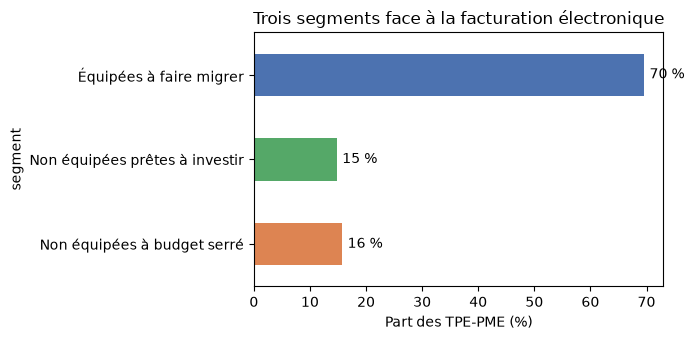

In [7]:
ordre = ["Équipées à faire migrer", "Non équipées prêtes à investir", "Non équipées à budget serré"]   # ordre d'affichage

fig, ax = plt.subplots(figsize=(7, 3.5))                          # zone de dessin de 7 × 3,5 pouces
poids_segments[ordre].plot(kind="barh", ax=ax, color=["#4C72B0", "#55A868", "#DD8452"])  # barres horizontales
ax.set_xlabel("Part des TPE-PME (%)")                             # libellé de l'axe horizontal
ax.set_title("Trois segments face à la facturation électronique") # titre
ax.invert_yaxis()                                                 # affiche le premier segment en haut
for i, v in enumerate(poids_segments[ordre]):                     # pour chaque barre
    ax.text(v + 1, i, f"{v:.0f} %", va="center")                  # écrit la valeur au bout de la barre
plt.tight_layout()                                                # ajuste les marges
plt.show()                                                        # affiche le graphique

## 6. Profil de chaque segment

In [8]:
profil = pd.DataFrame({s: [pct(df[df["segment"] == s], c) for c in indicateurs[1:]]   # indicateurs (sauf « équipée », redondant)
                       for s in ordre},
                      index=indicateurs[1:])
profil.round(1)

,Équipées à faire migrer,Non équipées prêtes à investir,Non équipées à budget serré
compta,86.9,43.9,36.1
petit_budget,41.6,0.0,100.0
benefice_ok,83.6,80.7,68.3
perte_temps_ok,17.5,19.5,24.9
peur_ok,45.2,37.5,44.7
retard_ok,21.1,18.9,29.6
sans_projet,27.8,25.0,48.6


In [9]:
taille_segment = pd.crosstab(df["segment"], df["taille"],         # répartition des tailles dans chaque segment
                             values=df["POIDS"], aggfunc="sum",   # en sommant les poids
                             normalize="index") * 100             # en % de chaque segment
taille_segment.loc[ordre].round(1)

taille,0 salarié,1 à 9 salariés,10 à 49 salariés,50 à 249 salariés
segment,,,,
Équipées à faire migrer,22.7,59.8,14.6,3.0
Non équipées prêtes à investir,23.3,68.4,7.1,1.2
Non équipées à budget serré,26.4,70.2,3.1,0.2


In [10]:
secteurs_reticents = (df[df["segment"] == "Non équipées à budget serré"]   # entreprises à budget serré uniquement
                      .groupby("secteur")["POIDS"].sum())               # poids total par secteur
(secteurs_reticents / secteurs_reticents.sum() * 100).sort_values(ascending=False).round(1).head(6)   # 6 premiers secteurs, en %

secteur
Services spécialisés - Techniques    18.0
Agriculture                          15.2
Commerce (détail et gros)            12.8
Bâtiment - Construction              11.2
Hébergement - Restauration            9.4
Services à la personne                7.9
Name: POIDS, dtype: float64

## 7. Prescripteurs : qui conseille chaque segment

Cette question oriente le choix des canaux de lancement : par qui faut-il passer pour toucher chaque segment ?

In [11]:
conseils = ["conseil_reseau_pro", "conseil_perso", "conseil_comptable", "conseil_cci", "sans_projet"]   # prescripteurs étudiés
noms = ["Réseaux professionnels", "Réseaux personnels", "Comptable", "CCI / CMA", "Aucun projet"]    # libellés lisibles

prescripteurs = pd.DataFrame({s: [pct(df[df["segment"] == s], c) for c in conseils] for s in ordre},
                             index=noms)
prescripteurs.round(1)

,Équipées à faire migrer,Non équipées prêtes à investir,Non équipées à budget serré
Réseaux professionnels,36.0,39.8,15.5
Réseaux personnels,20.8,24.6,16.1
Comptable,6.1,6.3,12.3
CCI / CMA,7.2,5.1,4.6
Aucun projet,27.8,25.0,48.6


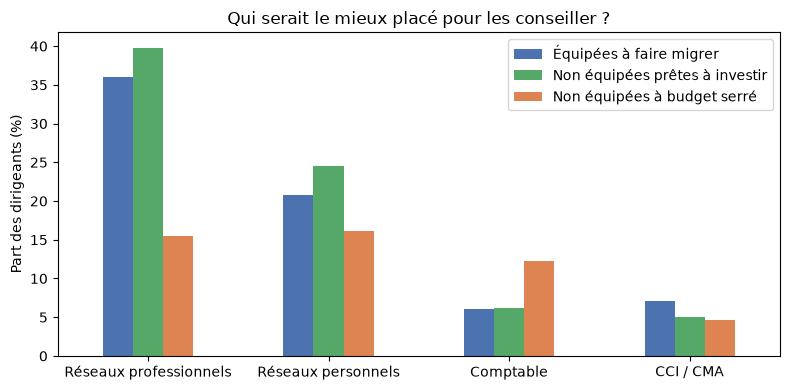

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))                            # zone de dessin
prescripteurs.drop("Aucun projet").plot(kind="bar", ax=ax,        # barres groupées, sans la ligne « aucun projet »
                                        color=["#4C72B0", "#55A868", "#DD8452"])
ax.set_ylabel("Part des dirigeants (%)")                          # libellé de l'axe vertical
ax.set_title("Qui serait le mieux placé pour les conseiller ?")   # titre
plt.xticks(rotation=0)                                            # libellés horizontaux
ax.legend(title="")                                               # légende sans titre
plt.tight_layout()
plt.show()

## 8. Conclusion

1. **Sept TPE-PME sur dix (69,5 %) ont déjà une solution de facturation.** Pour elles, l'enjeu n'est pas de s'équiper mais d'être conformes à la réforme. Le message doit répondre à la question « mon outil actuel suffira-t-il ? ».
2. **Les non-équipées forment deux segments de taille équivalente** : 14,8 % prêtes à investir et 15,7 % à budget serré, soit environ une TPE-PME sur six chacun.
3. **Le segment à budget serré est le plus fragile.** Il est composé à 97 % d'entreprises de moins de 10 salariés, seules 36 % ont un outil comptable, 49 % n'ont aucun projet numérique et 30 % se sentent en retard sur leur secteur. Il faut une offre d'entrée très accessible, qui couvre aussi la comptabilité de base, avec un accompagnement à la prise en main.
4. **Les prescripteurs diffèrent selon le segment.** Les entreprises prêtes à investir écoutent d'abord leurs réseaux professionnels (40 %). Les entreprises à budget serré citent deux fois plus souvent leur comptable (12 %, contre 6 % ailleurs). Le lancement doit donc combiner recommandation entre professionnels et partenariat avec les experts-comptables.
5. **Près d'un dirigeant sur deux craint pour ses données** (45 %), quel que soit le segment. La sécurité et l'hébergement des données doivent figurer dans le message principal.

Ces constats alimentent les trois personas (`docs/personas.md`) et le positionnement de Duo Facture.